In [2]:
from torchvision import transforms
from torchvision.datasets import EuroSAT

transform = transforms.ToTensor()
train = EuroSAT(root="./data", download=True, transform=transform)


100.0%


total de imagens: 27000
classes: 10 

  AnnualCrop             3000
  Forest                 3000
  HerbaceousVegetation   3000
  Highway                2500
  Industrial             2500
  Pasture                2000
  PermanentCrop          2500
  Residential            3000
  River                  2500
  SeaLake                3000

tamanho: (64, 64) | canais: RGB


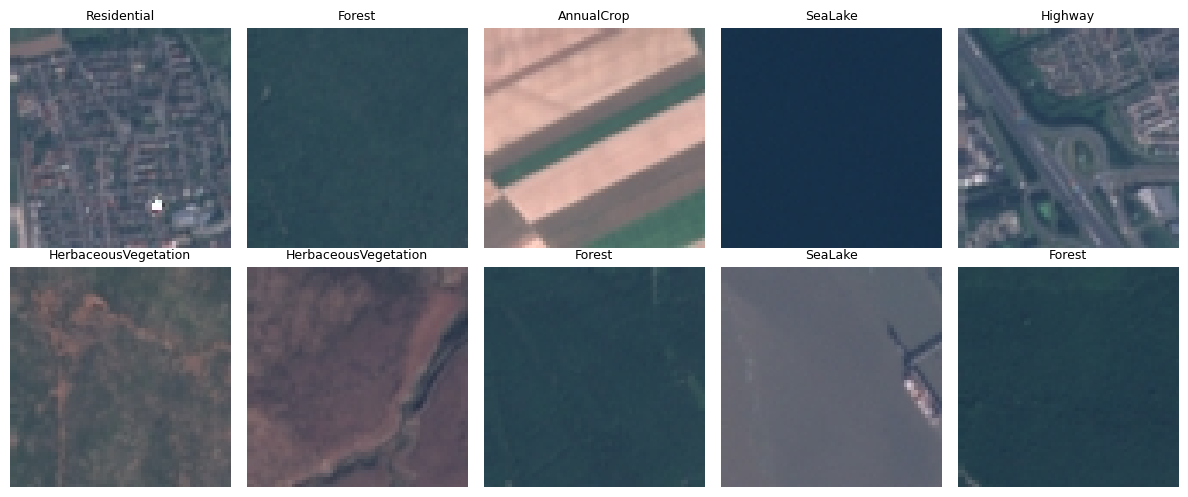

In [3]:
import random
from collections import Counter

import matplotlib.pyplot as plt
from torchvision.datasets import EuroSAT

ds = EuroSAT(root="./data", download=True)

print("total de imagens:", len(ds))
print("classes:", len(ds.classes), "\n")

cont = Counter(ds.targets)
for i, c in enumerate(ds.classes):
    print(f"  {c:22s} {cont[i]}")

img, y = ds[0]
print("\ntamanho:", img.size, "| canais:", img.mode)

random.seed(42)
idx = random.sample(range(len(ds)), 10)
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for a, i in zip(ax.ravel(), idx):
    im, t = ds[i]
    a.imshow(im)
    a.set_title(ds.classes[t], fontsize=9)
    a.axis("off")
plt.tight_layout()
plt.show()

In [4]:
import torch
from torchvision.datasets import EuroSAT
from torchvision.models import resnet18, ResNet18_Weights

pesos = ResNet18_Weights.IMAGENET1K_V1
classes_imagenet = pesos.meta["categories"]

print("a rede foi treinada para reconhecer", len(classes_imagenet), "categorias")
print("exemplos:", classes_imagenet[:6])

modelo = resnet18(weights=pesos)      # baixa ~45 MB na primeira vez
modelo.eval()
print("\núltima camada:", modelo.fc)   # Linear(512 -> 1000), uma saída por classe do ImageNet

prep = pesos.transforms()              # o pré-processamento oficial
ds = EuroSAT(root="./data", download=True)

for i in [0, 5000, 15000, 24000]:
    img, y = ds[i]
    with torch.no_grad():
        p = modelo(prep(img).unsqueeze(0)).softmax(1)
    top = p.topk(3)
    print(f"\nclasse real no EuroSAT: {ds.classes[y]}")
    for prob, idx in zip(top.values[0], top.indices[0]):
        print(f"   ResNet diz: {classes_imagenet[idx]:28s} {prob:.1%}")

a rede foi treinada para reconhecer 1000 categorias
exemplos: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray']
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Lucas/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%



última camada: Linear(in_features=512, out_features=1000, bias=True)

classe real no EuroSAT: AnnualCrop
   ResNet diz: bulletproof vest             5.6%
   ResNet diz: fire screen                  4.3%
   ResNet diz: microwave                    2.4%

classe real no EuroSAT: Forest
   ResNet diz: nematode                     22.2%
   ResNet diz: dugong                       12.1%
   ResNet diz: electric ray                 3.4%

classe real no EuroSAT: Pasture
   ResNet diz: bulletproof vest             53.9%
   ResNet diz: assault rifle                5.2%
   ResNet diz: tile roof                    2.2%

classe real no EuroSAT: SeaLake
   ResNet diz: space shuttle                2.8%
   ResNet diz: nematode                     2.7%
   ResNet diz: flagpole                     2.6%


In [5]:
aleatoria = resnet18(weights=None).eval()
with torch.no_grad():
    p_aleat = aleatoria(prep(ds[0][0]).unsqueeze(0)).softmax(1)
    p_treino = modelo(prep(ds[0][0]).unsqueeze(0)).softmax(1)

print(f"rede SEM treino  — maior probabilidade: {p_aleat.max():.4f}")
print(f"rede COM ImageNet — maior probabilidade: {p_treino.max():.4f}")

rede SEM treino  — maior probabilidade: 0.0017
rede COM ImageNet — maior probabilidade: 0.0562
